# Task 3: Netflix Audience Rating Classification
**Auspify ML Internship – Task 3**

### Objective & Project Overview
The objective is to predict a **target audience category** (`Kids`, `Older Kids`, `Teens`, `Adults`) from Netflix content metadata. The project maps 12 of the 14 raw ratings to four audience categories for this experiment.

### Dataset Description
The dataset contains **8,790 titles** with **10 attributes**:
- `show_id`: Unique title identifier
- `type`: Content format (`Movie` or `TV Show`)
- `title`: Title name
- `director`: Director name(s) or "Not Given"
- `country`: Producing country / countries
- `date_added`: Date when the title was added to Netflix
- `release_year`: Original release year
- `rating`: Raw parental guidelines rating (e.g., `TV-MA`, `TV-14`, `R`, `PG`, etc.)
- `duration`: Length in minutes (Movies) or seasons (TV Shows)
- `listed_in`: Comma-separated genre categories

In [1]:
import os
import sys
from pathlib import Path

# Suppress joblib/sklearn parallel worker warnings
os.environ.setdefault("PYTHONWARNINGS", "ignore::UserWarning:sklearn.utils.parallel")

# Add project root and src/ to sys.path
PROJECT_ROOT = Path("..").resolve()
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix

# Import modular project components from rating_classifier
from rating_classifier.config import (
    PATHS,
    TRAIN_CFG,
    RATING_MAP,
    CLASS_ORDER,
    RF_PARAM_GRID,
    NUMERIC_FEATURES,
)
from rating_classifier.data import load_data, map_audience
from rating_classifier.features import FeatureTransformer
from rating_classifier.models import get_model_specs, train_baselines, tune_random_forest
from rating_classifier.evaluate import compute_metrics, cross_validate, build_final_comparison

# Plotting configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10


## 1. Exploratory Data Analysis (EDA)
In this section, we load the raw dataset, inspect its structure, and examine key distributions including raw ratings, content format, release year patterns, and genre frequency.


In [2]:
raw_data_path = PROJECT_ROOT / "data" / "raw" / "Dataset.csv"
df_raw = load_data(raw_data_path)
print(f"Dataset shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")

Dataset shape: 8790 rows, 10 columns


### 1.1 Raw Rating Distribution (14 Classes)
Examining the distribution of the 14 raw MPAA and TV parental guidelines ratings.


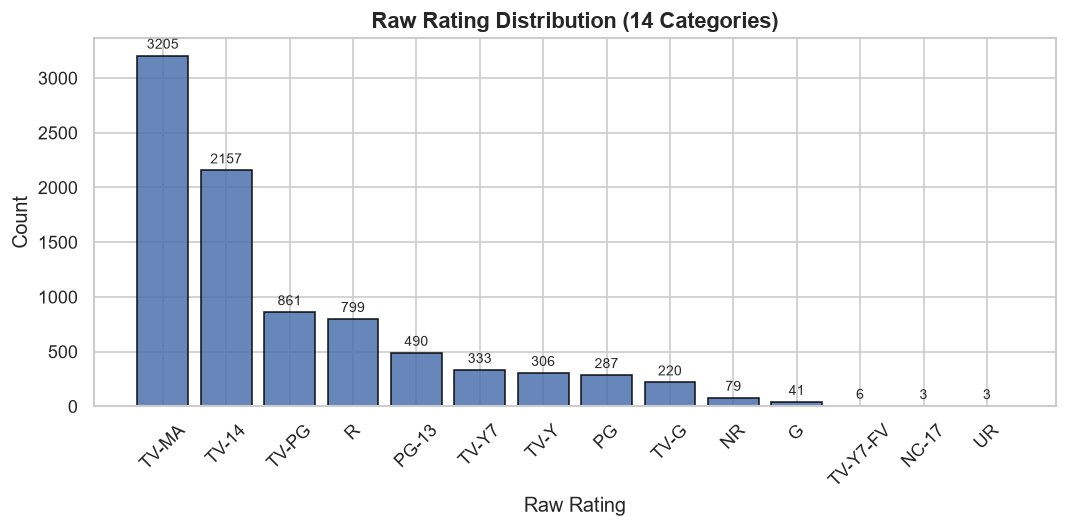

In [3]:
rating_counts = df_raw["rating"].value_counts()
rating_labels = rating_counts.index.to_numpy(dtype=str)
rating_values = rating_counts.to_numpy(dtype=float)

plt.figure(figsize=(9, 4.5))
bars = plt.bar(rating_labels, rating_values, color="#4C72B0", edgecolor="black", alpha=0.85)
plt.title("Raw Rating Distribution (14 Categories)", fontsize=13, fontweight="bold")
plt.xlabel("Raw Rating")
plt.ylabel("Count")
plt.xticks(rotation=45)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 35, f"{int(yval)}", ha="center", va="bottom", fontsize=8.5)
plt.tight_layout()
plt.show()


> **Interpretation:** The raw rating distribution displays acute class imbalance. Over 61% of all titles fall into either `TV-MA` (3,205) or `TV-14` (2,157), while niche ratings such as `TV-Y7-FV` (6) and `NC-17` (3) lack sufficient sample support for standalone learning. Furthermore, `NR` (79) and `UR` (3) do not convey audience maturity levels.


### 1.2 Content Type Distribution (Movie vs. TV Show)


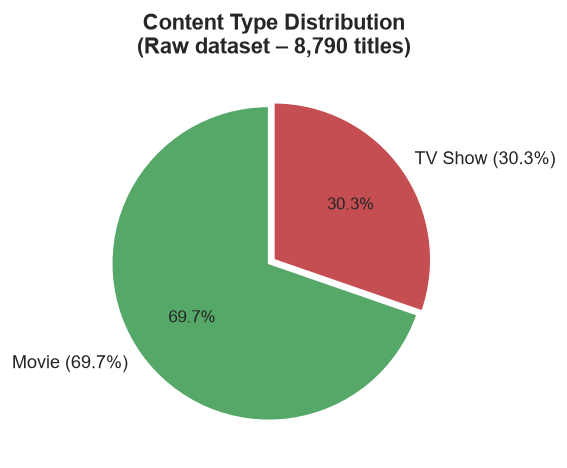

> **Interpretation (computed from raw dataset – 8790 titles):** Movies constitute **69.7%** (6126 titles) of Netflix's catalog, while TV Shows make up the remaining **30.3%** (2664 titles). This structural distinction dictates how duration is measured: minutes for Movies and seasons for TV Shows.

In [4]:
from IPython.display import display, Markdown

type_counts = df_raw["type"].value_counts()
type_values = type_counts.to_numpy(dtype=float)
type_pcts = df_raw["type"].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
plt.pie(
    type_values,
    labels=[f"{t} ({type_pcts[t]:.1f}%)" for t in type_counts.index],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#55A868", "#C44E52"],
    explode=(0.04, 0),
)
plt.title(
    "Content Type Distribution\n(Raw dataset – 8,790 titles)",
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

display(Markdown(
    f"> **Interpretation (computed from raw dataset – {len(df_raw)} titles):** "
    f"Movies constitute **{type_pcts['Movie']:.1f}%** ({type_counts['Movie']} titles) of Netflix's catalog, "
    f"while TV Shows make up the remaining **{type_pcts['TV Show']:.1f}%** ({type_counts['TV Show']} titles). "
    "This structural distinction dictates how duration is measured: minutes for Movies and seasons for TV Shows."
))


> **Interpretation:** Movies account for the majority of the Netflix catalog, while TV Shows make up the remaining portion (exact proportions calculated dynamically from `value_counts(normalize=True)` in the cell above on the raw 8,790-title dataset). This structural distinction dictates how duration is measured: minutes for Movies and seasons for TV Shows.


### 1.3 Release Year Distribution


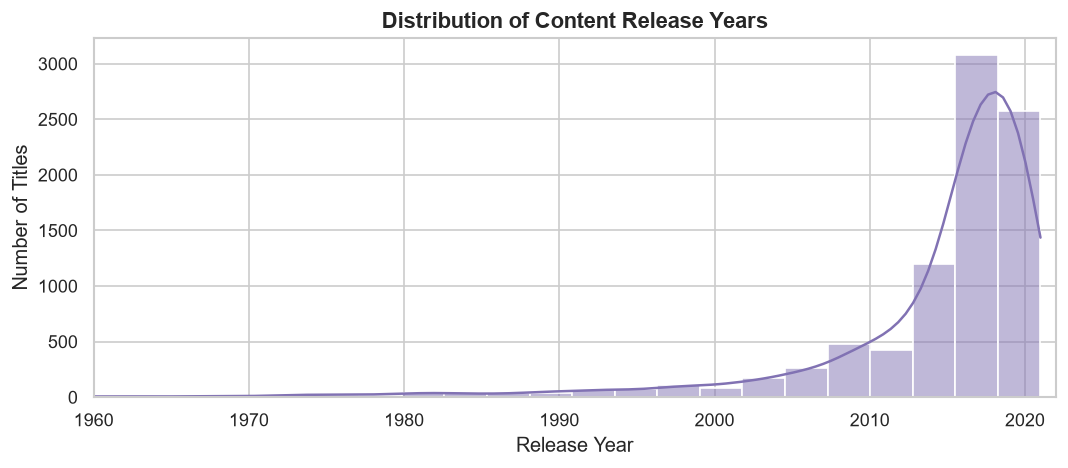

In [5]:
plt.figure(figsize=(9, 4))
sns.histplot(df_raw["release_year"], bins=35, kde=True, color="#8172B3")
plt.title("Distribution of Content Release Years", fontsize=13, fontweight="bold")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xlim(1960, 2022)
plt.tight_layout()
plt.show()


> **Interpretation:** The catalog is heavily skewed toward modern content released after 2010, peaking between 2017 and 2020. Historical titles released prior to 2000 form a small tail of the catalog.


### 1.4 Most Frequent Genres


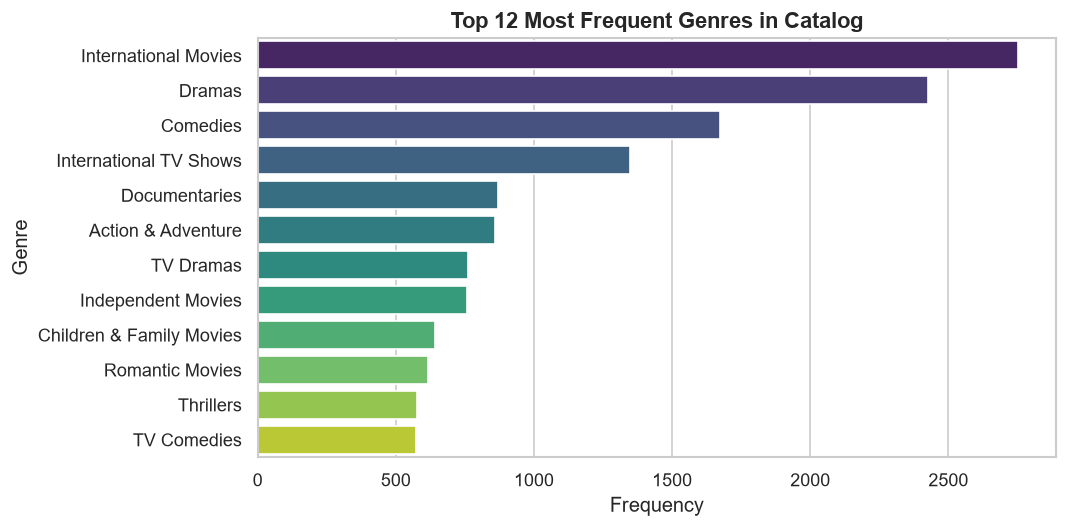

In [6]:
all_genres = df_raw["listed_in"].str.split(", ").explode().str.strip()
top_genres = all_genres.value_counts().head(12)

plt.figure(figsize=(9, 4.5))
sns.barplot(x=top_genres.values, y=top_genres.index, palette="viridis")
plt.title("Top 12 Most Frequent Genres in Catalog", fontsize=13, fontweight="bold")
plt.xlabel("Frequency")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


> **Interpretation:** `International Movies`, `Dramas`, and `Comedies` dominate the library. Crucially, dedicated family genres such as `Children & Family Movies` and `Kids' TV` serve as strong discriminative signals for young audience categories.


## 2. Audience Mapping & Target Categorization
### Rationale for Class Consolidation
The raw `rating` attribute contains 14 distinct categories with severe imbalance:
1. **Sparse Classes**: Categories like `NC-17` (3 samples), `TV-Y7-FV` (6 samples), and `UR` (3 samples) cannot support reliable statistical learning.
2. **Modeling Assumption**: The four project categories group film and television ratings for this experiment:
   - **Kids**: `TV-Y`, `TV-Y7`, `TV-Y7-FV`, `TV-G`, `G`
   - **Older Kids**: `TV-PG`, `PG`
   - **Teens**: `TV-14`, `PG-13`
   - **Adults**: `TV-MA`, `R`, `NC-17`
3. **Ambiguous Label Removal**: Titles marked `NR` (Not Rated, 79 titles) and `UR` (Unrated, 3 titles) carry no explicit maturity standard and cannot be reliably assigned without introducing label noise. Removing them (82 rows total) leaves 8,708 clean, supervised training records.


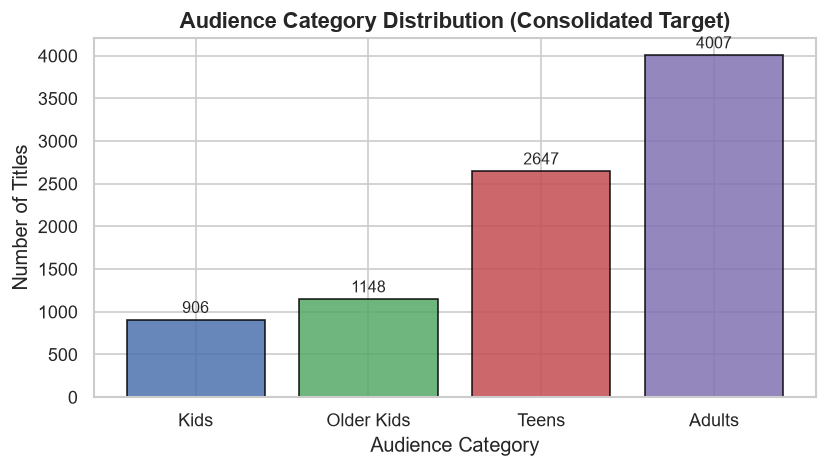

In [7]:
df = map_audience(df_raw, rating_map=RATING_MAP)

plt.figure(figsize=(7, 4))
colors = ["#4C72B0", "#55A868", "#C44E52", "#8172B3"]
counts = [df["audience"].value_counts()[c] for c in CLASS_ORDER]
bars = plt.bar(CLASS_ORDER, counts, color=colors, edgecolor="black", alpha=0.85)
plt.title("Audience Category Distribution (Consolidated Target)", fontsize=13, fontweight="bold")
plt.xlabel("Audience Category")
plt.ylabel("Number of Titles")
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 40, f"{int(yval)}", ha="center", va="bottom", fontsize=9.5)
plt.tight_layout()
plt.show()


> **Interpretation:** Each group has at least 906 examples. The training population remains imbalanced, with `Adults` (4,007), `Teens` (2,647), `Older Kids` (1,148), and `Kids` (906).


## 3. Feature Engineering
### Design & Engineering Logic
Feature engineering is fitted only after the stratified train/test split. The `FeatureTransformer` learns the training date median, top-country vocabulary, and genre vocabulary; test rows are transformed using those training-only parameters.

1. **Duration Decomposition**: Movies measure duration in minutes, while TV Shows measure duration in seasons.
2. **Temporal Features**: `year_added`, `month_added`, and `release_gap = year_added - release_year`.
3. **Metadata Flags**: `has_director`, `n_countries`, and `n_genres`.
4. **Categorical Encodings**: Primary country and frequent genres are learned from training data only.


In [8]:
# Split raw rows before any data-dependent feature learning
label_index = {label: index for index, label in enumerate(CLASS_ORDER)}
y = df["audience"].map(label_index)
if y.isna().any():
    raise ValueError("Audience mapping produced an unknown or missing target.")

df_train, df_test, y_train, y_test = train_test_split(
    df, y.astype(int),
    test_size=TRAIN_CFG.test_size,
    stratify=y,
    random_state=TRAIN_CFG.random_state,
)
feature_transformer = FeatureTransformer()
X_train = feature_transformer.fit_transform(df_train)
X_test = feature_transformer.transform(df_test)

print(f"Training set: {X_train.shape[0]} samples")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"Feature matrix shape: {X_train.shape}")
print(f"Total features created: {X_train.shape[1]}")

Training set: 6966 samples
Test set:     1742 samples
Feature matrix shape: (6966, 58)
Total features created: 58


## 4. Train/Test Split & Baseline Model Evaluation
The raw rows are split using an **80/20 stratified split** (`random_state=42`) before learning any date, country, or genre parameters. The scaler is fitted exclusively on `X_train`; tree models use the unscaled transformed features.

In [9]:
scaler = StandardScaler().fit(X_train)
model_specs = get_model_specs(random_state=TRAIN_CFG.random_state)
baseline_df = train_baselines(X_train, X_test, y_train, y_test, scaler, model_specs)
baseline_df.round(4)

,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Train Accuracy,Train Macro F1
3,Gradient Boosting,0.6441,0.5885,0.6883,0.5885,0.6174,0.6257,0.6815,0.6555
2,Random Forest,0.6257,0.6089,0.6116,0.6089,0.6103,0.6254,0.9885,0.9878
0,Logistic Regression,0.6051,0.6119,0.5948,0.6119,0.5988,0.6138,0.6118,0.6131
1,Decision Tree,0.5040,0.5535,0.6059,0.5535,0.5389,0.5156,0.5234,0.5741


> **Baseline Analysis:**
> - `Gradient Boosting` has the highest baseline test accuracy (**0.6441**) and Macro F1 (**0.6174**).
> - `Random Forest` achieves **0.6257** accuracy and **0.6103** Macro F1. Its train Macro F1 is **0.9878**.
> - `Logistic Regression` achieves **0.6051** accuracy and **0.5988** Macro F1.
> - `Decision Tree` achieves **0.5040** accuracy and **0.5389** Macro F1.


## 5. Hyperparameter Optimization (GridSearchCV)
We tune `RandomForestClassifier` with exhaustive grid search over structural parameters:
- `n_estimators`: `[200, 400]`
- `max_depth`: `[None, 15, 25]`
- `min_samples_leaf`: `[1, 3]`
- `max_features`: `["sqrt", 0.5]`
- Validation strategy: **3-fold StratifiedKFold** (`random_state=42`)
- Scoring objective: **Macro F1** (`scoring="f1_macro"`), prioritizing balanced minority class recognition.


In [10]:
best_rf = tune_random_forest(
    df_train, y_train,
    preprocessor=FeatureTransformer(),
    param_grid=RF_PARAM_GRID,
    random_state=TRAIN_CFG.random_state,
    cv_folds=TRAIN_CFG.grid_search_folds,
)
if not isinstance(best_rf, Pipeline):
    raise TypeError("Tuned Random Forest must be a preprocessing Pipeline.")
print("Optimized Random Forest Pipeline:")
print(best_rf)

Optimized Random Forest Pipeline:
Pipeline(steps=[('features', FeatureTransformer()),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=15,
                                        min_samples_leaf=3, n_estimators=400,
                                        n_jobs=-1, random_state=42))])


## 6. Comprehensive Model Evaluation & Diagnostics
We compare held-out model scores, inspect the tuned Random Forest's normalized confusion matrix and feature importances, and run a 5-fold sensitivity check. The CLI logs the per-class classification report.


In [11]:
y_pred = best_rf.predict(df_test)
tuned_metrics = compute_metrics(y_test, y_pred, class_order=CLASS_ORDER)
train_pred = best_rf.predict(df_train)
train_metrics = compute_metrics(y_train, train_pred, class_order=CLASS_ORDER)
tuned_metrics.update({
    "Train Accuracy": train_metrics["Accuracy"],
    "Train Macro F1": train_metrics["Macro F1"],
})

final_comparison = build_final_comparison(baseline_df, tuned_metrics)
print("=== Final Model Comparison Table ===")
display(final_comparison.round(4))

=== Final Model Comparison Table ===


,Model,Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Train Accuracy,Train Macro F1
0,Random Forest (Tuned),0.6383,0.6388,0.6408,0.6388,0.6376,0.6429,0.7353,0.7400
1,Gradient Boosting,0.6441,0.5885,0.6883,0.5885,0.6174,0.6257,0.6815,0.6555
2,Random Forest,0.6257,0.6089,0.6116,0.6089,0.6103,0.6254,0.9885,0.9878
3,Logistic Regression,0.6051,0.6119,0.5948,0.6119,0.5988,0.6138,0.6118,0.6131
4,Decision Tree,0.5040,0.5535,0.6059,0.5535,0.5389,0.5156,0.5234,0.5741


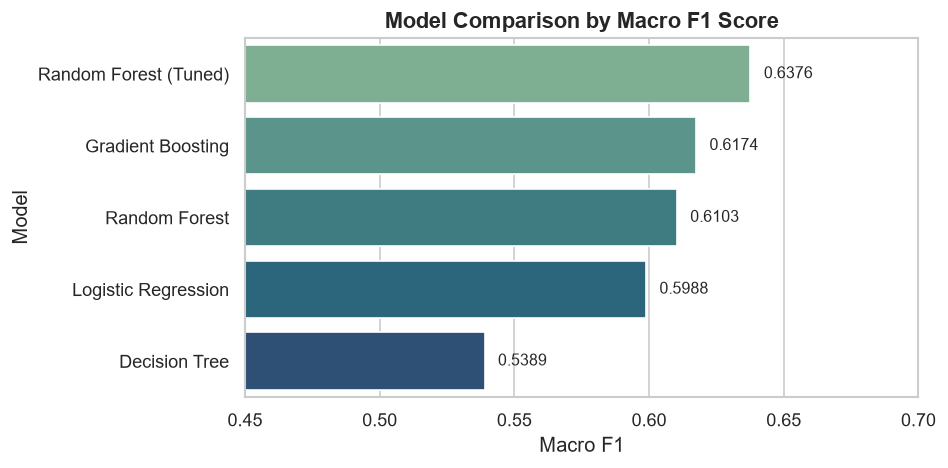

In [12]:
# Visualization: Model Comparison
plt.figure(figsize=(8, 4))
sns.barplot(data=final_comparison, y="Model", x="Macro F1", palette="crest")
plt.title("Model Comparison by Macro F1 Score", fontsize=13, fontweight="bold")
plt.xlabel("Macro F1")
plt.xlim(0.45, 0.70)
for position, (_, row) in enumerate(final_comparison.iterrows()):
    plt.text(float(row["Macro F1"]) + 0.005, float(position), f"{row['Macro F1']:.4f}", va="center", fontsize=9.5)
plt.tight_layout()
plt.show()


In [13]:
# 5-fold cross-validation refits the feature transformer inside every fold
cv_res = cross_validate(best_rf, df, y.astype(int), cv=TRAIN_CFG.cv_folds, scoring="f1_macro")
print(f"5-Fold CV Macro F1: {cv_res['mean']:.4f} ? {cv_res['std']:.4f}")

5-Fold CV Macro F1: 0.5870 ? 0.0343


### 6.1 Normalized Confusion Matrix Analysis


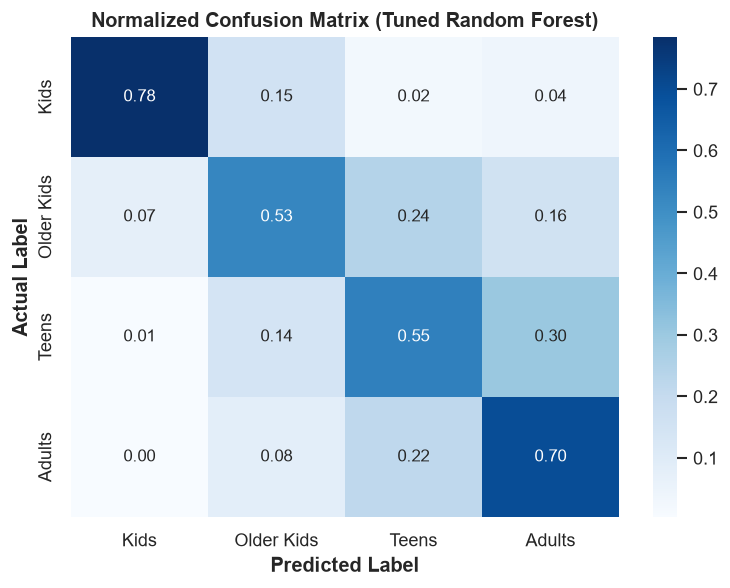

In [14]:
cm = confusion_matrix(y_test, y_pred, normalize="true")

plt.figure(figsize=(6.5, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=CLASS_ORDER,
    yticklabels=CLASS_ORDER,
    cbar=True
)
plt.xlabel("Predicted Label", fontweight="bold")
plt.ylabel("Actual Label", fontweight="bold")
plt.title("Normalized Confusion Matrix (Tuned Random Forest)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


> **Confusion Matrix Diagnostics:**
> - **Kids** (78% recall) and **Adults** (70% recall) exhibit high classification fidelity.
> - **Older Kids** is predicted as **Teens** for 24% of its test rows and **Kids** for 7%.
> - **Teens** is predicted as **Adults** for 30% of its test rows and **Older Kids** for 14%.
> - The boundary between adjacent maturity brackets (`Older Kids` vs. `Teens`, and `Teens` vs. `Adults`) is inherently fluid based purely on catalog metadata.


### 6.2 Top-15 Feature Importances


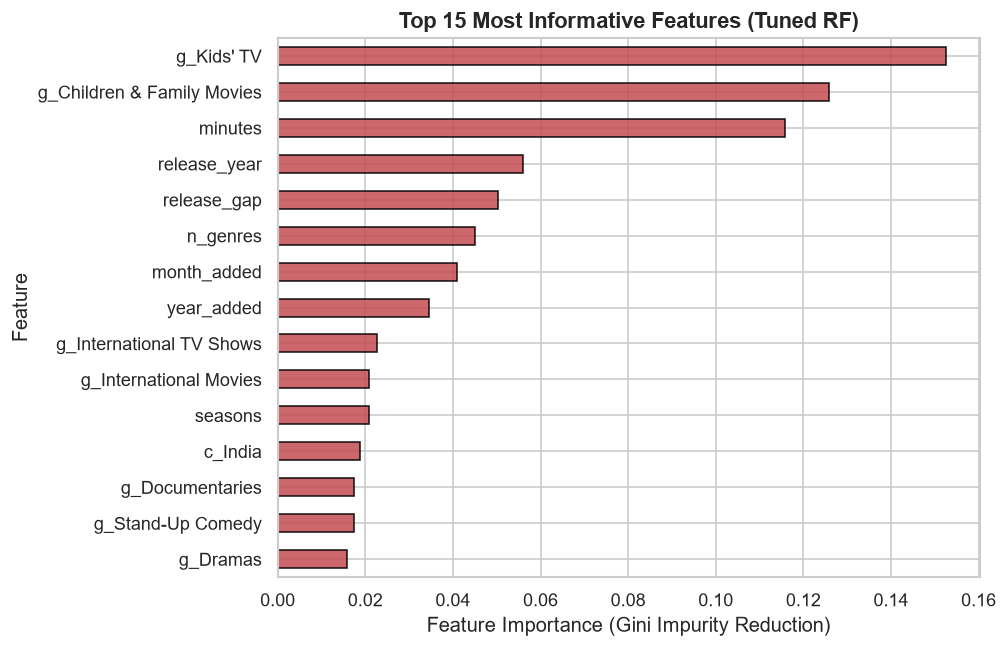

Top 10 Feature Importances:
g_Kids' TV                    0.1526
g_Children & Family Movies    0.1258
minutes                       0.1158
release_year                  0.0560
release_gap                   0.0503
n_genres                      0.0450
month_added                   0.0410
year_added                    0.0345
g_International TV Shows      0.0228
g_International Movies        0.0210
dtype: float64


In [15]:
importances = pd.Series(
    best_rf.named_steps["model"].feature_importances_,
    index=best_rf.named_steps["features"].get_feature_names_out(),
).sort_values(ascending=False).head(15)

plt.figure(figsize=(8.5, 5.5))
importances[::-1].plot(kind="barh", color="#C44E52", edgecolor="black", alpha=0.85)
plt.title("Top 15 Most Informative Features (Tuned RF)", fontsize=13, fontweight="bold")
plt.xlabel("Feature Importance (Gini Impurity Reduction)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Top 10 Feature Importances:")
print(importances.head(10).round(4))

> **Feature Importance Diagnostics:**
> 1. `g_Kids' TV` (0.1526) and `g_Children & Family Movies` (0.1258) rank highest by mean impurity reduction.
> 2. `minutes` (0.1158) ranks third.
> 3. Temporal features include `release_year` (0.0560), `release_gap` (0.0503), and `year_added` (0.0345).


## 7. Conclusions & Strategic Discussion
### Summary of Findings
- The modular ML pipeline achieves **0.6383 Test Accuracy** and **0.6376 Macro F1** with the tuned Random Forest, outperforming all baseline models on balanced performance.
- A 5-fold sensitivity check with the selected hyperparameters gives **0.5870 ± 0.0343** Macro F1. It reuses rows involved in tuning.
- Five normalized title keys occur in both train and test, including one pair with identical features and the same label. Scores are from a row-level split.

### Model Selection: Gradient Boosting vs. Tuned Random Forest
Grid search selected the Random Forest hyperparameters by training-fold **Macro F1**, which weights all four classes equally. On the held-out test, `Gradient Boosting` had the highest accuracy (**0.6441**) and the **Tuned Random Forest** had the highest Macro F1 (**0.6376**).

### Hypotheses: Why Older Kids and Teens Overlap
> *Note: the following are plausible hypotheses based on the data characteristics; they have not been validated through additional experiments.*

- **Hypothesis 1 – Thematic Continuum**: The boundary between `PG` ("Older Kids") and `PG-13` / `TV-14` ("Teens") likely hinges on nuanced dialog, intensity of action violence, and thematic maturity rather than coarse genre labels. Metadata alone may not capture these subtle distinctions.
- **Hypothesis 2 – Shared Catalog Genres**: Both classes frequently share broad genre tags such as `Action & Adventure`, `Comedies`, and `Dramas`, which may reduce the discriminative power of genre-based features at this boundary.

### Hypotheses: Why Overall Accuracy May Cap at ~64%
> *Note: the following are plausible hypotheses; additional ablation studies would be needed to confirm their individual impact.*

- **Hypothesis 1 – Absence of Narrative Content**: The dataset consists exclusively of high-level metadata (runtime, year, countries, coarse genres). Rating boards determine maturity levels from *content substance* (violence, profanity, sexual content, substance abuse, dark themes), which are likely unobservable from metadata alone.
- **Hypothesis 2 – Lack of Synopsis / Plot Text**: Without natural-language descriptions, two movies sharing nearly identical structural metadata (e.g. a 95-minute American Drama released in 2019) may differ in rating solely based on content tone — a distinction that we hypothesize cannot be captured without textual signals.

### Recommended Future Work
1. **NLP Feature Engineering**: Apply TF-IDF or pre-trained transformer embeddings (e.g. MiniLM / BERT) on content descriptions/synopses to capture language and thematic markers.
2. **External Data Enrichment**: Ingest IMDb / TMDb parental advisories (explicit ratings for violence, profanity, and substance use).
3. **Hierarchical / Multi-Stage Modeling**: Build a two-stage classifier (Stage 1: Minor vs. Adult; Stage 2: Kids vs. Older Kids / Teens vs. Adults) to disentangle the nested maturity hierarchy.

---
**Auspify ML Internship – Task 3**

